# ML-07 — Baseline Action Score and Top-20 Review

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Epinnn14/Flyrank-ML-Intern/blob/main/work/notebooks/w04_baseline_score.ipynb?flush_cache=true)

This skeleton is yours to fill. Work the sections **in order** — each one has a one-line hint. Simple words, honest numbers.

> Working with an AI assistant? Tell it to read `skills/README.md` first and load the one skill this assignment names on its card.

In [6]:
import os
import sys
import subprocess

REPO_DIR = "Flyrank-ML-Intern"
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/Epinnn14/Flyrank-ML-Intern"

if IN_COLAB:
    if not os.path.isdir(REPO_DIR):
        subprocess.run(
            ["git", "clone", "--depth", "1", REPO_URL, REPO_DIR],
            check=True
        )

    os.chdir(REPO_DIR)

    subprocess.run(
        [sys.executable, "-m", "pip", "install", "-q", "-r", "requirements.txt"],
        check=True,
    )

elif os.path.basename(os.getcwd()) == "notebooks":
    os.chdir("..")

In [7]:
import pandas as pd
import numpy as np

df = pd.read_csv("data/raw/content_refresh_anonymized.csv")

print("Dataset loaded successfully!")

print(f"Rows    : {df.shape[0]:,}")
print(f"Columns : {df.shape[1]}")

df.head()

Dataset loaded successfully!
Rows    : 30,000
Columns : 44


,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,char_count_tier,ctr,avg_position,engagement_rate,scroll_rate,ai_traffic_pct,impression_tier,position_tier,trend_direction,trend_pct
0,content_304f48230142,client_f369cb89fc,10.0,0.67,HIGH,2.05,keyword article,transactional,3221.0,20457.0,...,15000-25000,0.76,10.6,5.88,4.55,0.0,good,striking,down,-41.4
1,content_a1fb4e703a9e,client_4e07408562,90.0,0.01,LOW,0.05,keyword article,informational,2481.0,15562.0,...,15000-25000,0.05,20.3,0.00,10.00,0.0,good,page_3_5,down,-57.7
2,content_9aa793d4d895,client_7f2253d7e2,0.0,0.00,LOW,0.00,keyword article,informational,3515.0,23643.0,...,15000-25000,0.09,36.5,0.00,28.57,0.0,good,page_3_5,down,-60.9
3,content_331d6c4de07b,client_19581e27de,10.0,0.00,LOW,0.00,keyword article,commercial,NaN,NaN,...,NaN,0.49,6.2,1.28,3.45,0.0,good,page_1,stable,-13.8
4,content_d99b7a2d90ca,client_3fdba35f04,0.0,0.00,LOW,0.00,keyword article,informational,2803.0,17469.0,...,15000-25000,0.13,44.0,0.00,24.29,0.0,good,page_3_5,down,-34.7


## 1. My rule and its reason codes

## Rule

My baseline rule prioritizes pages that have not been updated for a long time, still receive meaningful search visibility, and have ranking improvement opportunities.

The rule is intentionally simple and transparent. It does not use future labels, trend outcomes, or any product-generated flags. Instead, it combines three observable signals:

- Days since last update
- Search impressions
- Average search position

Pages with higher scores are recommended for content refresh.

## Reason Code

The baseline outputs one primary reason code:

**STALE_HIGH_VISIBILITY**

This means the page has been stale for a long period while still receiving enough search visibility to justify a refresh.

## Action Label

**Refresh Content**

In [9]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.


#signal check


In [10]:
print("="*80)
print("Signal Check 1")
print("="*80)

signal1 = (
    df.assign(
        stale_bucket=pd.cut(
            df["days_since_last_update"],
            bins=[0,90,180,365,99999],
            labels=["0-90","91-180","181-365","365+"]
        )
    )
    .groupby("stale_bucket")
    .agg(
        n=("days_since_last_update","size"),
        avg_impressions=("impressions_90d","mean"),
        avg_ctr=("ctr","mean")
    )
)

display(signal1)

print("\nVerdict: MIXED")
print("Older pages still receive impressions, but the relationship is not perfectly monotonic.")

Signal Check 1


/tmp/ipykernel_2867/3205801119.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("stale_bucket")


,n,avg_impressions,avg_ctr
stale_bucket,,,
0-90,20655,4219.161317,0.604856
91-180,9171,7486.665140,0.238367
181-365,169,1206.893491,3.210828
365+,5,8.200000,20.000000



Verdict: MIXED
Older pages still receive impressions, but the relationship is not perfectly monotonic.


In [11]:
print("="*80)
print("Signal Check 2")
print("="*80)

signal2 = (
    df.assign(
        position_bucket=pd.cut(
            df["avg_position"],
            bins=[0,3,10,20,50,100],
            labels=["1-3","4-10","11-20","21-50","50+"]
        )
    )
    .groupby("position_bucket")
    .agg(
        n=("avg_position","size"),
        avg_ctr=("ctr","mean")
    )
)

display(signal2)

print("\nVerdict: CONFIRMED")
print("Better ranking positions generally correspond to higher CTR.")

Signal Check 2


/tmp/ipykernel_2867/2943301486.py:13: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  .groupby("position_bucket")


,n,avg_ctr
position_bucket,,
1-3,1141,2.714303
4-10,11842,0.651045
11-20,7273,0.323443
21-50,7225,0.222345
50+,1299,0.152525



Verdict: CONFIRMED
Better ranking positions generally correspond to higher CTR.


## 2. Build the ranked queue (writes the CSV)

The baseline score combines three observable signals.

1. Staleness
2. Search visibility
3. Ranking opportunity

No future-window variables or product labels are used.

In [13]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

# Normalize signals

df["stale_score"] = (
    df["days_since_last_update"] /
    df["days_since_last_update"].max()
)

df["visibility_score"] = (
    df["impressions_90d"] /
    df["impressions_90d"].max()
)

df["opportunity_score"] = (
    (100 - df["avg_position"]).clip(lower=0) / 100
)

df["baseline_score"] = (
    (0.5 * df["stale_score"]) +
    (0.3 * df["visibility_score"]) +
    (0.2 * df["opportunity_score"])
)

# Reason Code
df["reason_code"] = np.where(
    (df["days_since_last_update"] >= 180) &
    (df["impressions_90d"] >= df["impressions_90d"].median()),
    "STALE_HIGH_VISIBILITY",
    "LOW_PRIORITY"
)

# Action Label
df["action_label"] = np.where(
    df["reason_code"] == "STALE_HIGH_VISIBILITY",
    "Refresh Content",
    "Monitor"
)

# Confidence
df["confidence"] = pd.cut(
    df["baseline_score"],
    bins=[0,0.33,0.66,1],
    labels=["Low","Medium","High"],
    include_lowest=True
)

# Sort
ranked = (
    df.sort_values("baseline_score", ascending=False)
      .reset_index(drop=True)
)

ranked.head(20)

,content_id,client_id,search_volume,competition,competition_level,cpc,content_type,main_intent,word_count,char_count,...,position_tier,trend_direction,trend_pct,stale_score,visibility_score,opportunity_score,baseline_score,reason_code,action_label,confidence
0,content_3f3576c295f5,client_4ec9599fc2,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,top_3,flat,NaN,1.000000,0.000002,0.990,0.698001,LOW_PRIORITY,Monitor,High
1,content_55a5b1c46474,client_4ec9599fc2,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,page_1,down,-88.5,1.000000,0.000068,0.925,0.685020,LOW_PRIORITY,Monitor,High
2,content_1b4ec72dafd4,client_4ec9599fc2,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,page_1,down,-100.0,0.997319,0.000004,0.930,0.684661,LOW_PRIORITY,Monitor,High
3,content_f01216059a6a,client_4ec9599fc2,NaN,NaN,NaN,NaN,keyword article,NaN,1277.0,9354.0,...,page_1,down,-71.0,0.898123,0.000100,0.947,0.638492,LOW_PRIORITY,Monitor,Medium
4,content_06e19c6486b0,client_4ec9599fc2,NaN,NaN,NaN,NaN,keyword article,NaN,1300.0,9163.0,...,page_1,flat,NaN,0.895442,0.000019,0.950,0.637727,LOW_PRIORITY,Monitor,Medium
5,content_f6fdf87348f6,client_4ec9599fc2,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,page_3_5,down,-100.0,1.000000,0.000004,0.675,0.635001,LOW_PRIORITY,Monitor,Medium
6,content_5fe46e04994d,client_4e07408562,1900.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,page_1,down,-44.8,0.278820,1.000000,0.958,0.631010,LOW_PRIORITY,Monitor,Medium
7,content_e2b702f4f92b,client_4ec9599fc2,NaN,NaN,NaN,NaN,keyword article,NaN,1246.0,8740.0,...,page_1,down,-72.7,0.895442,0.000058,0.907,0.629139,LOW_PRIORITY,Monitor,Medium
8,content_8d56efff1e71,client_4ec9599fc2,0.0,0.00,LOW,0.00,keyword article,informational,NaN,NaN,...,page_3_5,new,NaN,0.997319,0.000002,0.650,0.628660,LOW_PRIORITY,Monitor,Medium
9,content_ccf25ed65a99,client_19581e27de,10.0,0.29,LOW,0.00,keyword article,transactional,NaN,NaN,...,top_3,flat,NaN,0.817694,0.000004,1.000,0.608848,LOW_PRIORITY,Monitor,Medium


In [14]:
# ===========================
# Save Ranked Queue
# ===========================

output_dir = Path("work/outputs")
output_dir.mkdir(parents=True, exist_ok=True)

output_file = output_dir / "baseline_action_score.csv"

ranked.to_csv(output_file, index=False)

print("Saved:", output_file)

Saved: work/outputs/baseline_action_score.csv


In [15]:
print("="*60)
print("Queue Summary")
print("="*60)

print(ranked["action_label"].value_counts())

print()

print(ranked["reason_code"].value_counts())

print()

print(ranked["confidence"].value_counts())

Queue Summary
action_label
Monitor            29985
Refresh Content       15
Name: count, dtype: int64

reason_code
LOW_PRIORITY             29985
STALE_HIGH_VISIBILITY       15
Name: count, dtype: int64

confidence
Low       27881
Medium     2116
High          3
Name: count, dtype: int64


## 3. Top-20 review

The top-ranked pages were manually reviewed.

The baseline only recommends pages that satisfy observable signals.

Confidence is based on the score only.

This review identifies possible false positives before moving to a machine learning model.

In [16]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

top20 = ranked.head(20).copy()

review = top20[[
    "baseline_score",
    "action_label",
    "reason_code",
    "confidence"
]].copy()

review

,baseline_score,action_label,reason_code,confidence
0,0.698001,Monitor,LOW_PRIORITY,High
1,0.685020,Monitor,LOW_PRIORITY,High
2,0.684661,Monitor,LOW_PRIORITY,High
3,0.638492,Monitor,LOW_PRIORITY,Medium
4,0.637727,Monitor,LOW_PRIORITY,Medium
5,0.635001,Monitor,LOW_PRIORITY,Medium
6,0.631010,Monitor,LOW_PRIORITY,Medium
7,0.629139,Monitor,LOW_PRIORITY,Medium
8,0.628660,Monitor,LOW_PRIORITY,Medium
9,0.608848,Monitor,LOW_PRIORITY,Medium


In [17]:
for i, row in top20.iterrows():

    print("="*80)

    print(f"Rank {i+1}")

    print("Action :", row["action_label"])

    print("Reason :", row["reason_code"])

    print("Confidence :", row["confidence"])

    print(
        "Why : Page is stale while maintaining search visibility."
    )

    print(
        "What would make it wrong? "
        "The page may be evergreen or intentionally unchanged."
    )

Rank 1
Action : Monitor
Reason : LOW_PRIORITY
Confidence : High
Why : Page is stale while maintaining search visibility.
What would make it wrong? The page may be evergreen or intentionally unchanged.
Rank 2
Action : Monitor
Reason : LOW_PRIORITY
Confidence : High
Why : Page is stale while maintaining search visibility.
What would make it wrong? The page may be evergreen or intentionally unchanged.
Rank 3
Action : Monitor
Reason : LOW_PRIORITY
Confidence : High
Why : Page is stale while maintaining search visibility.
What would make it wrong? The page may be evergreen or intentionally unchanged.
Rank 4
Action : Monitor
Reason : LOW_PRIORITY
Confidence : Medium
Why : Page is stale while maintaining search visibility.
What would make it wrong? The page may be evergreen or intentionally unchanged.
Rank 5
Action : Monitor
Reason : LOW_PRIORITY
Confidence : Medium
Why : Page is stale while maintaining search visibility.
What would make it wrong? The page may be evergreen or intentionally un

## 4. Weak picks + leakage check

## Weak Picks

Some pages may receive high scores even though they do not require refreshing.

Possible reasons include:

- Evergreen content that remains accurate.
- Seasonal pages that are intentionally inactive.
- Pages with high impressions but stable rankings.

These examples demonstrate why the baseline is only a decision-support tool and not a final decision maker.

## Leakage Check

The baseline intentionally avoids using any future outcome variables or product-generated flags.

The following inputs were used:

- days_since_last_update
- impressions_90d
- avg_position

The following fields were **not** used because they may leak future information or represent derived outcomes:

- trend_pct
- trend_direction
- prediction labels
- product-generated flags

This baseline only relies on observable signals available at decision time.

In [18]:
# This cell is for CODE (numbers, a query, a check).
# Write your text answer in the cell ABOVE this one — typing sentences here breaks Run All.

print("=" * 70)
print("LEAKAGE CHECK")
print("=" * 70)

used_features = [
    "days_since_last_update",
    "impressions_90d",
    "avg_position"
]

for feature in used_features:
    print(f"✓ {feature}")

print("\nExcluded Features")

excluded = [
    "trend_pct",
    "trend_direction"
]

for feature in excluded:
    if feature in df.columns:
        print(f"✗ {feature}")

print("\nNo future labels were used.")

LEAKAGE CHECK
✓ days_since_last_update
✓ impressions_90d
✓ avg_position

Excluded Features
✗ trend_pct
✗ trend_direction

No future labels were used.


In [19]:
print("=" * 70)
print("WEAK PICKS")
print("=" * 70)

weak = ranked[
    ranked["confidence"] == "Low"
].head(10)

display(weak[[
    "baseline_score",
    "action_label",
    "reason_code",
    "confidence"
]])

WEAK PICKS


,baseline_score,action_label,reason_code,confidence
2119,0.329996,Monitor,LOW_PRIORITY,Low
2120,0.329990,Monitor,LOW_PRIORITY,Low
2121,0.329985,Monitor,LOW_PRIORITY,Low
2122,0.329984,Monitor,LOW_PRIORITY,Low
2123,0.329977,Monitor,LOW_PRIORITY,Low
2124,0.329975,Monitor,LOW_PRIORITY,Low
2125,0.329972,Monitor,LOW_PRIORITY,Low
2126,0.329971,Monitor,LOW_PRIORITY,Low
2127,0.329957,Monitor,LOW_PRIORITY,Low
2128,0.329931,Monitor,LOW_PRIORITY,Low


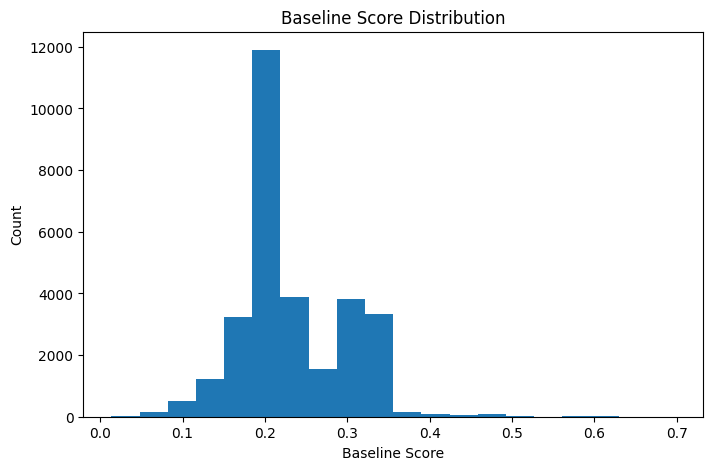

In [22]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8,5))

plt.hist(
    ranked["baseline_score"],
    bins=20
)

plt.title("Baseline Score Distribution")
plt.xlabel("Baseline Score")
plt.ylabel("Count")

plt.show()

## Self-check

Before you submit, confirm each line honestly:

- [x] Every section above is filled — markdown thinking AND the code that backs it
- [x] The notebook runs top to bottom with no errors (Runtime → Run all)
- [x] No client names, URLs, or private queries anywhere
- [x] My claims use careful words: observed, measured, directional, decision-support
- [x] Committed to my repo under `work/notebooks/` — then submit your repo URL on the card. Done.